# 检索、选择证据、检查引用 / Research Agent

问题要求查找教材固定资料库中的事实。策略先选择检索词，实际检索文档，
再选择证据并提取答案。答案正确与引用正确分别评分，避免只看最终字符串。
我们直接复用教材已有的可运行基准，再加入训练前后条件一致的独立评估。

默认 CPU、三个种子、220 轮。候选检索词由任务预先提供，答案是选中文档的字段，
训练对象为共享特征的线性策略，检索使用教材提供的固定资料库。


In [1]:
import importlib.util
import subprocess
import sys

if importlib.util.find_spec("matplotlib") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "matplotlib>=3.8,<4"])

import copy
import hashlib
import inspect
import json
import os
from pathlib import Path
import random
import urllib.request
import matplotlib.pyplot as plt

OUTPUT = Path(os.getenv("HANDS_ON_LAB_OUTPUT", "lab-output")) / "agentic-research"
OUTPUT.mkdir(parents=True, exist_ok=True)
print("A fixed local corpus; no external search API or model download.")


A fixed local corpus; no external search API or model download.


## 1. 固定源码和数据 / Pin source and data

下载的基准固定到仓库提交，并检查 SHA-256，避免网站更新导致实验悄悄变化。
首次运行需要联网获取这个 Python 文件，之后会复用通过校验的本地缓存。
资料库中的文档包含标题、正文、答案和文档编号。


In [2]:
COMMIT = "4bce68267c0e17107ab3b42b35efb2dffa3f777d"
SOURCE = "docs/chapter22_agentic/code/deep_research_rl_benchmark.py"
EXPECTED_SHA256 = "22a043be7e04532629b6f89f8ba3fecc3accfce744b1ee4fba1212b5813e2a02"
cache = OUTPUT / "benchmark.py"
if not cache.exists():
    url = f"https://raw.githubusercontent.com/walkinglabs/hands-on-modern-rl/{COMMIT}/{SOURCE}"
    cache.write_bytes(urllib.request.urlopen(url, timeout=30).read())
assert hashlib.sha256(cache.read_bytes()).hexdigest() == EXPECTED_SHA256
spec = importlib.util.spec_from_file_location("research_benchmark", cache)
benchmark = importlib.util.module_from_spec(spec)
sys.modules[spec.name] = benchmark
spec.loader.exec_module(benchmark)
print("Verified source:", EXPECTED_SHA256)
print(inspect.getsource(benchmark.run_episode))


Verified source: 22a043be7e04532629b6f89f8ba3fecc3accfce744b1ee4fba1212b5813e2a02
def run_episode(
    policy: LinearSoftmaxPolicy,
    task: Task,
    rng: random.Random,
    temperature: float = 1.0,
    greedy: bool = False,
) -> tuple[float, dict[str, object]]:
    q_features = [query_features(task.question, query) for query in task.query_options]
    q_idx, q_probs = policy.choose(policy.query_weights, q_features, temperature, greedy)
    query = task.query_options[q_idx]

    results = search(query, rng)
    d_features = [doc_features(task.question, query, doc, rank) for rank, doc in enumerate(results)]
    d_idx, d_probs = policy.choose(policy.doc_weights, d_features, temperature, greedy)
    doc = results[d_idx]

    score = reward(task, doc.answer, doc.doc_id)
    trace = {
        "query_idx": q_idx,
        "query_probs": q_probs,
        "query_features": q_features,
        "doc_idx": d_idx,
        "doc_probs": d_probs,
        "doc_features": d_features,
        "query":

## 2. 分开训练问题与评估问题 / Hold out questions

前七个问题训练，后三个问题评估，它们的目标文档互不相同。
检索语料库共用，因为评估阶段本来就需要能查到新问题的证据。
评估问题的标签不进入训练更新；我们保留同样的检索扰动种子、温度和动作选择方式。


In [3]:
training, heldout = benchmark.TASKS[:7], benchmark.TASKS[7:]
assert {t.support_doc_id for t in training}.isdisjoint(t.support_doc_id for t in heldout)
print({"train_questions": len(training), "heldout_questions": len(heldout),
       "corpus_documents": len(benchmark.DOCS)})


def matched_evaluation(policy, greedy):
    scores, exact, citations = [], [], []
    for repeat in range(20):
        sampled_policy = copy.deepcopy(policy)
        sampled_policy.rng = random.Random(1000 + repeat)
        for index, task in enumerate(heldout):
            score, trace = benchmark.run_episode(sampled_policy, task,
                random.Random(2000 + 100 * repeat + index), temperature=0.7, greedy=greedy)
            scores.append(score)
            exact.append(trace["answer"].lower() == task.gold_answer.lower())
            citations.append(trace["doc"].doc_id == task.support_doc_id)
    return {"reward": sum(scores) / len(scores), "answer_exact": sum(exact) / len(exact),
            "citation_support": sum(citations) / len(citations)}


print("Matched evaluator ready: same seeds, temperature and action mode before/after.")


{'train_questions': 7, 'heldout_questions': 3, 'corpus_documents': 12}
Matched evaluator ready: same seeds, temperature and action mode before/after.


## 3. 比较前后的同一种策略 / Matched evaluation

训练选择检索词与证据的线性权重。我们同时报告贪心评估和重复采样评估，
前后分别使用一致设置。训练曲线来自训练问题的奖励，测试指标单独保存。
下表分别列出答案准确率、引用正确率与总奖励。


[
  {
    "seed": 3,
    "before": {
      "greedy": {
        "reward": 1.0,
        "answer_exact": 1.0,
        "citation_support": 1.0
      },
      "sampled": {
        "reward": 0.2,
        "answer_exact": 0.2,
        "citation_support": 0.2
      }
    },
    "after": {
      "greedy": {
        "reward": 1.0,
        "answer_exact": 1.0,
        "citation_support": 1.0
      },
      "sampled": {
        "reward": 1.0,
        "answer_exact": 1.0,
        "citation_support": 1.0
      }
    }
  },
  {
    "seed": 7,
    "before": {
      "greedy": {
        "reward": 1.0,
        "answer_exact": 1.0,
        "citation_support": 1.0
      },
      "sampled": {
        "reward": 0.2,
        "answer_exact": 0.2,
        "citation_support": 0.2
      }
    },
    "after": {
      "greedy": {
        "reward": 1.0,
        "answer_exact": 1.0,
        "citation_support": 1.0
      },
      "sampled": {
        "reward": 1.0,
        "answer_exact": 1.0,
        "citation_support

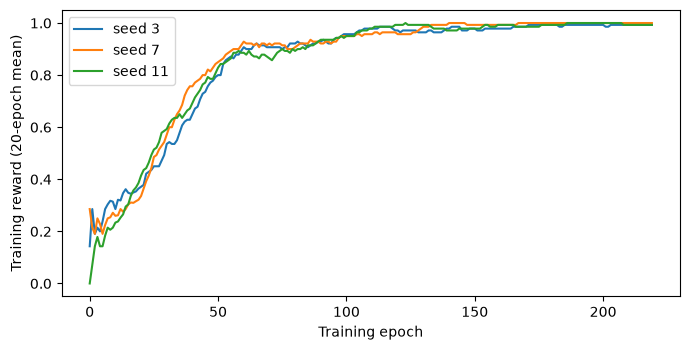

{
  "question": "Which agentic reasoning report uses a GRPO-style recipe to make smaller models competitive?",
  "query": "GRPO style recipe smaller model competitive agentic reasoning",
  "retrieved": [
    "rstar2-paper",
    "tongyi-paper",
    "web-shepherd-paper",
    "distractor-rag"
  ],
  "chosen_doc": "rstar2-paper",
  "answer": "rStar2-Agent",
  "reward": 1.0
}


In [4]:
runs, histories, policies = [], [], []
for seed in [3, 7, 11]:
    policy = benchmark.LinearSoftmaxPolicy(random.Random(seed))
    before = {mode: matched_evaluation(policy, mode == "greedy")
              for mode in ["greedy", "sampled"]}
    history = benchmark.train(policy, training, epochs=220)
    after = {mode: matched_evaluation(policy, mode == "greedy")
             for mode in ["greedy", "sampled"]}
    runs.append({"seed": seed, "before": before, "after": after})
    histories.append(history)
    policies.append(policy)
print(json.dumps(runs, indent=2))
fig, ax = plt.subplots(figsize=(7, 3.6))
for seed, history in zip([3, 7, 11], histories):
    smoothed = [sum(history[max(0, i - 19):i + 1]) / min(i + 1, 20)
                for i in range(len(history))]
    ax.plot(smoothed, label=f"seed {seed}")
ax.set(xlabel="Training epoch", ylabel="Training reward (20-epoch mean)", ylim=(-0.05, 1.05))
ax.legend()
fig.tight_layout()
fig.savefig(OUTPUT / "training.png", dpi=120)
plt.show()

score, trace = benchmark.run_episode(policies[0], heldout[0], random.Random(2000), greedy=True)
retrieved = benchmark.search(trace["query"], random.Random(2000))
trajectory = {"question": heldout[0].question, "query": trace["query"],
              "retrieved": [doc.doc_id for doc in retrieved], "chosen_doc": trace["doc"].doc_id,
              "answer": trace["answer"], "reward": score}
weights = [{"query": policy.query_weights, "document": policy.doc_weights} for policy in policies]
(OUTPUT / "policy-weights.json").write_text(json.dumps(weights, indent=2))
metrics = {"runs": runs, "fixed_heldout_trace": trajectory, "source_sha256": EXPECTED_SHA256,
           "train_questions": len(training), "heldout_questions": len(heldout), "epochs": 220,
           "algorithm": "Feature policy with REINFORCE-style baseline updates"}
(OUTPUT / "metrics.json").write_text(json.dumps(metrics, indent=2))
assert trajectory["chosen_doc"] in trajectory["retrieved"]
print(json.dumps(trajectory, indent=2))


## 完成检查 / Checklist
- [ ] 验证源码哈希与训练、评估问题划分。
- [ ] 分开查看答案准确率、引用正确率与总奖励。
- [ ] 保留检索词、返回文档、选中证据与策略权重。

## 练习 / Exercise
答案错误、引用正确时，填入总奖励。提示：代码中答案占 0.75，引用占 0.25。


In [5]:
RUN_EXERCISE = False
answer = None
if RUN_EXERCISE:
    assert abs(answer - 0.25) < 1e-6
else:
    print("Fill answer, then enable RUN_EXERCISE.")


Fill answer, then enable RUN_EXERCISE.


## 参考资料 / References
- [DeepResearch 评测](https://walkinglabs.github.io/hands-on-modern-rl/chapter24_deep_research/deep-research-eval)：答案、证据、过程与成本。
- [浏览器研究轨迹](https://walkinglabs.github.io/hands-on-modern-rl/chapter24_deep_research/browser-rl-harness)：从固定语料继续走向网页工具。
- [教材基准源码](https://github.com/walkinglabs/hands-on-modern-rl/blob/4bce68267c0e17107ab3b42b35efb2dffa3f777d/docs/chapter22_agentic/code/deep_research_rl_benchmark.py)：本实验固定使用的版本。


## 本次运行结果

CPU · Python 3.12.13 · 1.93 s

[查看完整结果页](https://walkinglabs.github.io/hands-on-modern-rl/lab-results/agentic-research-zh.html)
